# 06 — Exploratory analysis: speakers, conversations and delivery

**Stage question.** What do these conversations look like — who talks how much, how turns are exchanged, what the replies are, and how pitch and loudness vary between people and between moments — before any model is fitted?

> **Exploratory, not confirmatory.** Nothing in this notebook tests a hypothesis. It also deliberately does **not** look at whether a partner's delivery relates to the reply's delivery. That relationship is the study's primary question (H1). Examining it before the instrument is calibrated would open a route from the data into analysis choices. It is estimated only in the core-test stage, under the matched-donor nulls.

| | |
|---|---|
| **Purpose** | Understand the data the study rests on, and show the evidence behind three design choices: per-speaker standardisation of delivery, a per-file loudness offset, and the turn-level unit of analysis. |
| **Input** | Tables stored by notebooks 02–04: turns, candidate pairs, channel QC, frame tracks, turn voicing. Section 5 downloads a few short audio clips for listening. |
| **Processing** | Descriptive summaries in `src/analysis/eda.py` (tested): talk share, turn-level rates, per-file pitch and intensity summaries, between-speaker variance share. |
| **Output** | `results/eda/` (summary tables), `figures/06_eda/`, and a few short listening clips saved to Drive in `data/samples/` (git-ignored). |
| **Scientific assumptions** | Only usable channels (notebook 04) are summarised. Frame-level pitch and intensity summaries describe the measurement; they are not the eight target dimensions, which are computed in the prosody-targets stage. |
| **Failure modes** | Reading exploratory patterns as findings; drawing site-level conclusions from a pilot of 40 sessions. |
| **What to look at** | Talk balance, the reply-timing distribution, the between-speaker share of pitch variation, and the spread of file loudness. |

**Terms.**
- **Talk share**: one speaker's share of the speaking time in an interaction.
- **Floor transfer offset**: time from the end of one turn to the start of the reply. Negative values are overlaps. In conversation it typically clusters around 0–300 ms.
- **Speaking rate (coarse)**: words per second over a turn, pauses included. The target measure, *articulation rate*, excludes pauses and comes later.
- **Median F0**: a speaker's typical pitch in one file. **log-F0 span**: the 5th-to-95th-percentile range of log-pitch, the same construction as the pitch-span target, here over a whole file.
- **Between-speaker share (η²)**: the fraction of a measure's variance explained by *who* is speaking. A high value means raw values mostly identify the speaker, which is why the targets are standardised per speaker.

In [1]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
runtime        colab   python 3.13.16   cpus 2
memory         11.5 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   11.9 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint e1a10dc2c7145664
artifacts      manifest=True, metadata=True, transcripts=True, turns=True, audio_pass_sessions=293, channel_qc=True


**Runtime check.** The cell above prints free disk on the project root (Drive on Colab) and on the scratch disk where audio briefly lives, memory, CPU count, GPU, the code fingerprint, and which pipeline artifacts already exist. The code fingerprint identifies the exact source and configuration that ran; it is written into every run record and is how a result produced on Drive is matched back to the repository.

In [2]:
# Parameters
STAGE = 'sample'
SAVE_AUDIO_SAMPLES = True     # save a few short clips to Drive (data/samples/) and play them below
EMBED_PLAYERS = True          # False keeps the notebook file small (no in-page players)

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.paths import paths
from src.analysis.eda import talk_share, turn_rates, file_prosody_summary, between_group_share
from src.runtime import write_run_record
from src.viz import style

P = paths().ensure()
style.apply()
OUT = P.results / 'eda'
OUT.mkdir(parents=True, exist_ok=True)
from src.config import FeatureConfig
TAG = f'{STAGE}__{FeatureConfig().pitch_segment_source}'
FIGDIR = f'06_eda__{TAG}'

selected = pd.read_csv(P.results / 'acquisition' / f'selected_sessions_{STAGE}.csv')
sessions = set(selected['session_key'])
qc = pd.read_parquet(P.processed / 'channel_qc.parquet')
qc = qc[qc['session_key'].isin(sessions)]
ok = qc[qc['failure'].isna()]
turns = pd.read_parquet(P.processed / 'turns.parquet')
turns = turns[turns['session_key'].isin(sessions)]
pairs = pd.read_parquet(P.processed / 'pairs_candidates.parquet')
pairs = pairs[pairs['session_key'].isin(sessions)]
site = qc.drop_duplicates('session_key').set_index('session_key')['vendor_id']
print(f"{len(sessions)} sessions, {ok['participant_key'].nunique()} speakers, "
      f"{ok['interaction_key'].nunique()} interactions, {(~turns['embedded']).sum():,} turns, {len(pairs):,} pairs")

250 sessions, 500 speakers, 2822 interactions, 108,837 turns, 105,993 pairs


## 1. How much each person talks

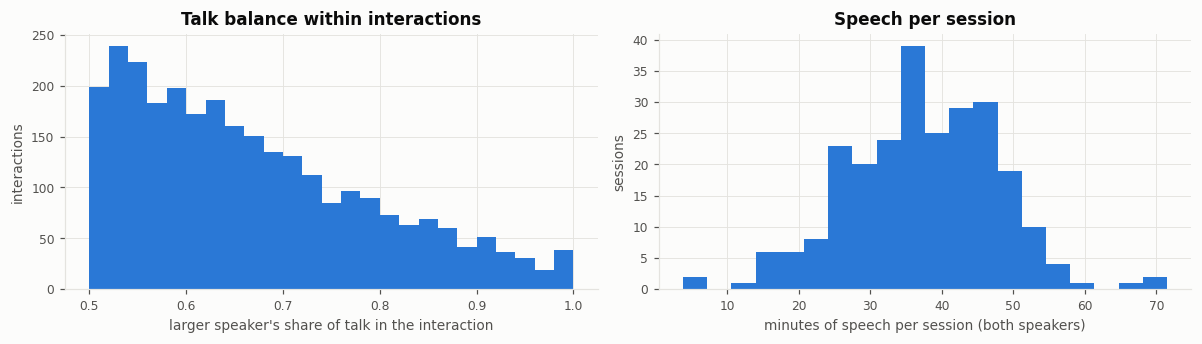

median dominant share 0.64; interactions where one person has over 80% of the talk: 17.0%


In [6]:
share = talk_share(turns)
dom = share.groupby('interaction_key')['share'].max()
per_session = turns.assign(d=turns['duration']).groupby('session_key')['d'].sum() / 60
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(dom, bins=np.linspace(0.5, 1, 26), color=style.SERIES[0])
axes[0].set_xlabel("larger speaker's share of talk in the interaction")
axes[0].set_ylabel('interactions'); axes[0].set_title('Talk balance within interactions')
axes[1].hist(per_session, bins=20, color=style.SERIES[0])
axes[1].set_xlabel('minutes of speech per session (both speakers)')
axes[1].set_ylabel('sessions'); axes[1].set_title('Speech per session')
fig.tight_layout(); style.save(fig, P.figures, FIGDIR, 'talk_balance'); plt.show()
print(f"median dominant share {dom.median():.2f}; interactions where one person has over 80% of the talk: {(dom > 0.8).mean():.1%}")

**What is plotted.** Left: in each interaction, the share of speaking time taken by whoever talked more (0.5 = perfectly balanced, 1 = monologue). Right: total minutes of speech per session.

**Why it matters.** The prompts often ask one person to tell a story and the other to respond. Unbalanced interactions yield fewer, longer turns and fewer pairs. The replies in them are also more often short responses. That is part of the conversational-function mix the situation analysis later tests.

**What would indicate a problem.** A mass at 1.0, meaning interactions where one channel is effectively silent, would point to a transcription or channel failure rather than to conversation.

**Conclusion.** Record the median balance. Imbalance is a property of the prompts and is kept, not corrected.

## 2. How turns are exchanged

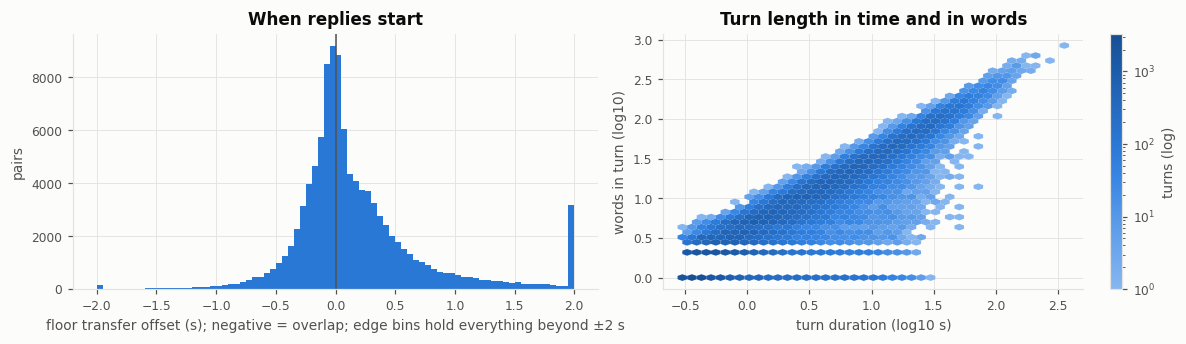

floor transfer offset quantiles (s): {0.1: -0.303, 0.25: -0.114, 0.5: 0.04, 0.75: 0.342, 0.9: 0.835}
offsets beyond ±2 s (shown in the edge bins): 3.0%
coarse speaking rate, turns over 1 s: median 3.00 words/s


In [7]:
tr = turn_rates(turns)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
g = pairs['gap_s'].clip(-2, 2)
axes[0].hist(g, bins=np.linspace(-2, 2, 81), color=style.SERIES[0])
axes[0].axvline(0, color=style.INK_SECONDARY, lw=1)
axes[0].set_xlabel('floor transfer offset (s); negative = overlap; edge bins hold everything beyond ±2 s')
axes[0].set_ylabel('pairs'); axes[0].set_title('When replies start')
m = tr['duration'] > 0.3
from matplotlib.colors import LinearSegmentedColormap
ramp = LinearSegmentedColormap.from_list('coda_seq', list(style.SEQUENTIAL))
hb = axes[1].hexbin(np.log10(tr.loc[m, 'duration']), np.log10(tr.loc[m, 'n_words']), gridsize=40,
                    cmap=ramp, mincnt=1, bins='log', linewidths=0)
fig.colorbar(hb, ax=axes[1], label='turns (log)')
axes[1].set_xlabel('turn duration (log10 s)'); axes[1].set_ylabel('words in turn (log10)')
axes[1].set_title('Turn length in time and in words')
fig.tight_layout(); style.save(fig, P.figures, FIGDIR, 'turn_exchange'); plt.show()
q = pairs['gap_s'].quantile([.1, .25, .5, .75, .9]).round(3)
print('floor transfer offset quantiles (s):', q.to_dict())
print(f"offsets beyond ±2 s (shown in the edge bins): {(pairs['gap_s'].abs() > 2).mean():.1%}")
print(f"coarse speaking rate, turns over 1 s: median {tr.loc[tr['duration'] > 1, 'words_per_s'].median():.2f} words/s")

**What is plotted.** Left: the time from the end of each partner turn to the start of the reply. Right: turn duration against word count on log scales; darker cells hold more turns.

**Why it matters.** The left panel is a standard signature of natural conversation. Replies cluster just after the partner stops, with a large share starting in overlap. A distribution that matches the published signature is evidence that the turn construction captures real exchanges. The right panel shows that duration and word count track each other, which is why the N1 donor is matched on both. Both describe how much a turn contains.

**What would indicate a problem.** A flat or strongly shifted offset distribution (seconds rather than hundreds of milliseconds) would suggest turns stitched across long silences. Horizontal streaks in the right panel would mean turns with many seconds but one word, which points to timing errors.

**Conclusion.** Record the median offset and the overlap share. The overlap share is also the size of the exposure to echo suppression examined in notebook 04.

## 3. What the replies are

A first look at the text of reply turns. The question mark is only a surface marker, used here for a count, not a label. Conversational-function labels are assigned in the situation stage by a text-only classifier, validated against 300 hand-labelled pairs.

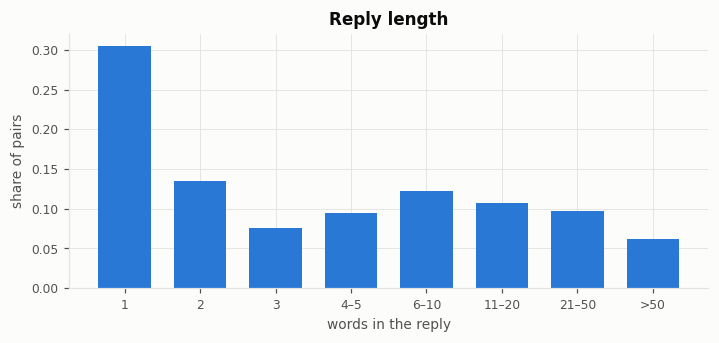

,one- or two-word replies
text,
yeah,8216
right,1668
okay,1294
mm-hmm,1211
oh,719
i,678
yes,629
like,599
and,437


partner turns ending with '?': 5.5% (5,854 pairs) — a lower bound on question → answer pairs


In [8]:
rep = tr.set_index('turn_id').loc[pairs['reply_turn_id']]
par = tr.set_index('turn_id').loc[pairs['partner_turn_id']]
wbins = [0, 1, 2, 3, 5, 10, 20, 50, 1e9]
labels = ['1', '2', '3', '4–5', '6–10', '11–20', '21–50', '>50']
cnt = pd.cut(rep['n_words'], wbins, labels=labels).value_counts().reindex(labels)
fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.bar(cnt.index.astype(str), cnt.values / cnt.sum(), color=style.SERIES[0], width=0.7)
ax.set_xlabel('words in the reply'); ax.set_ylabel('share of pairs'); ax.set_title('Reply length')
style.save(fig, P.figures, FIGDIR, 'reply_length'); plt.show()
top = rep.loc[rep['n_words'] <= 2, 'text'].str.lower().str.strip(' .,!?').value_counts().head(12)
display(top.to_frame('one- or two-word replies'))
print(f"partner turns ending with '?': {par['ends_with_question_mark'].mean():.1%} "
      f"({int(par['ends_with_question_mark'].sum()):,} pairs) — a lower bound on question → answer pairs")

**What is plotted.** The distribution of reply length in words, and the most frequent one- and two-word replies.

**Why it matters.** Short replies are mostly acknowledgements ("yeah", "right", "okay"). They make up the backchannel-adjacent category of the situation analysis, and they carry the least voicing, which ties them to feature droppage. The question-mark count indicates whether a question → answer stratum can reach the specification's minimum of 200 pairs. Over the full sample, the count should comfortably exceed that.

**What would indicate a problem.** Frequent short replies that are fillers of the other speaker ("um" attributed to the wrong channel) would suggest speaker attribution errors.

**Conclusion.** Record the reply-length mix. It is a property of the corpus that the conditioning set already accounts for through reply word count.

## 4. Pitch and loudness: between people and between moments

Per usable file: the speaker's median pitch, the file's log-F0 span, and the median intensity over voiced frames.

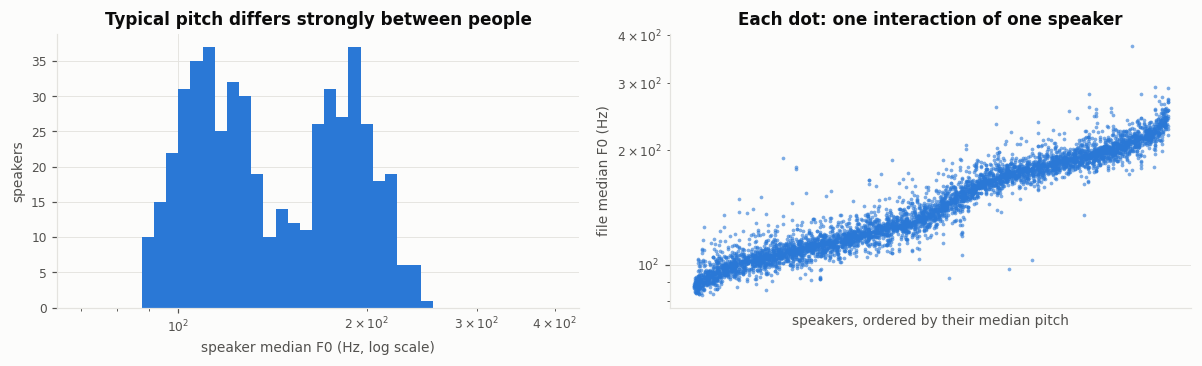

,share of variance between speakers
median F0 (log),0.954
log-F0 span,0.660
median intensity,0.960
intensity span,0.526


In [9]:
fp = file_prosody_summary(P, qc)
fp.to_csv(OUT / f'file_prosody_summary_{TAG}.csv', index=False)
spk = fp.groupby('participant_key')['median_f0_hz'].median()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(spk, bins=np.logspace(np.log10(70), np.log10(400), 40), color=style.SERIES[0])
axes[0].set_xscale('log'); axes[0].set_xlabel('speaker median F0 (Hz, log scale)')
axes[0].set_ylabel('speakers'); axes[0].set_title('Typical pitch differs strongly between people')
order = spk.sort_values().index
pos = {s: i for i, s in enumerate(order)}
axes[1].scatter(fp['participant_key'].map(pos), fp['median_f0_hz'], s=6, color=style.SERIES[0], alpha=0.6)
axes[1].set_yscale('log'); axes[1].set_xticks([])
axes[1].set_xlabel('speakers, ordered by their median pitch'); axes[1].set_ylabel('file median F0 (Hz)')
axes[1].set_title('Each dot: one interaction of one speaker')
fig.tight_layout(); style.save(fig, P.figures, FIGDIR, 'pitch_between_within'); plt.show()

eta = pd.Series({
    'median F0 (log)': between_group_share(fp.assign(v=np.log(fp['median_f0_hz'])), 'v', 'participant_key'),
    'log-F0 span': between_group_share(fp, 'log_f0_span_p5_p95', 'participant_key'),
    'median intensity': between_group_share(fp, 'median_intensity_db', 'participant_key'),
    'intensity span': between_group_share(fp, 'intensity_span_p5_p95', 'participant_key'),
}, name='share of variance between speakers')
eta.to_frame().to_csv(OUT / f'between_speaker_share_{TAG}.csv')
eta.round(3).to_frame()

**What is plotted.** Left: each speaker's typical pitch. Right: for every speaker, ordered by that typical pitch, the median pitch of each of their interactions. The table gives, for four file-level measures, the share of variance that lies between speakers rather than within a speaker.

**Why it matters.** Typical pitch differs by roughly an octave between low and high voices, while one person's interactions sit close together. So raw pitch mostly identifies *who* is talking. A model predicting raw reply pitch would learn speaker identity, not conversational delivery. This is why the targets are z-scored per speaker (following Levitan and Hirschberg). The table shows how much of each measure is a speaker constant.

**What would indicate a problem.** Within-speaker spread across interactions as large as the between-speaker spread in median pitch. That would point to octave errors or to channels carrying the wrong voice (see notebook 04's octave profile).

**Conclusion.** Record the between-speaker shares. The more a measure is a speaker constant, the more per-speaker standardisation matters, and the more important the held-out-speaker rule becomes (statistics for a test speaker come only from that speaker's other turns).

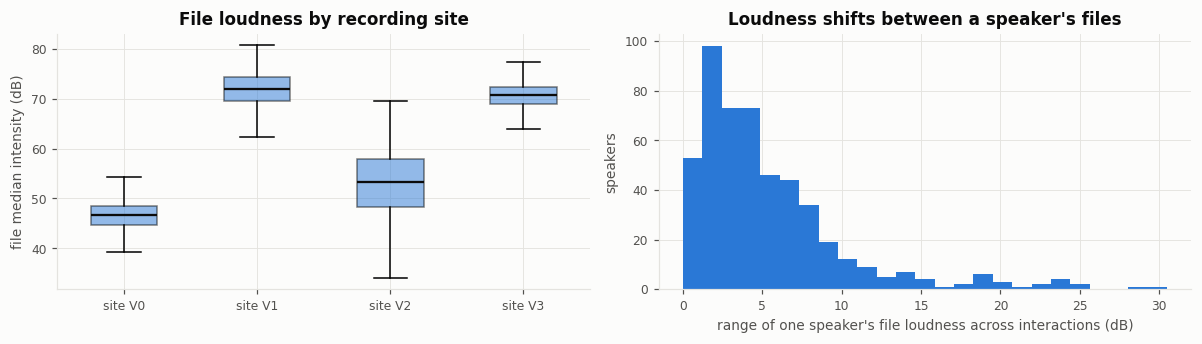

median within-speaker range of file loudness: 4.0 dB


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sites = sorted(fp['vendor_id'].unique())
data = [fp.loc[fp['vendor_id'] == s, 'median_intensity_db'] for s in sites]
bp = axes[0].boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                     medianprops={'color': style.INK, 'linewidth': 1.5})
for b in bp['boxes']:
    b.set_facecolor(style.SERIES[0]); b.set_alpha(0.5)
axes[0].set_xticks(range(1, len(sites) + 1), [f'site V{s}' for s in sites])
axes[0].set_ylabel('file median intensity (dB)'); axes[0].set_title('File loudness by recording site')
spread = fp.groupby('participant_key')['median_intensity_db'].agg(lambda s: s.max() - s.min())
axes[1].hist(spread, bins=25, color=style.SERIES[0])
axes[1].set_xlabel("range of one speaker's file loudness across interactions (dB)")
axes[1].set_ylabel('speakers'); axes[1].set_title('Loudness shifts between a speaker\'s files')
fig.tight_layout(); style.save(fig, P.figures, FIGDIR, 'loudness_offsets'); plt.show()
print(f"median within-speaker range of file loudness: {spread.median():.1f} dB")

**What is plotted.** Left: the typical loudness of files from each recording site. Right: for each speaker, how much the typical loudness of their files varies from one interaction to the next.

**Why it matters.** Each file was scaled so its peak hits a fixed level. A file's absolute loudness therefore reflects its single loudest moment as much as the speaker's voice, and it moves from file to file for the same person. This is the evidence for the per-file loudness offset in the conditioning set. Without it, intensity differences between turns would partly be differences between files.

**What would indicate a problem.** Within-speaker ranges of a fraction of a decibel would mean normalisation did not vary and the offset is unnecessary. Ranges of tens of decibels would mean intensity is barely comparable even within a speaker, which would weaken the energy block.

**Conclusion.** Record the median within-speaker range. The numeric form of the offset is fixed in the conditioning-set stage.

## 5. Listening to the data

Everything above is numbers and pictures. This section lets you *hear* the recordings the numbers came from, which is the best way to understand what the measurements are measuring.

A few short clips (20 seconds each) are downloaded, cut, played here, and **saved to your Drive** in `data/samples/`. They are chosen by a fixed, seeded rule that looks only at channel quality and turn structure, never at any delivery measure: one interaction per recording site, plus the interaction with the most overlapping speech, the one with the clipped loud transient described in notebook 05, and the one with the longest turns, where the window is placed on the longest turn itself.

The long-turn clip is there because extended turns carry most of the speech in this corpus: turns of two seconds and longer are 36% of turns but roughly 90% of all speech time, and turns over five seconds alone carry about 77%. These clips illustrate; they enter no analysis, and the sample is never selected on turn length.

Each clip is **stereo with one speaker per ear**: put headphones on. The first speaker is in the left ear and the second in the right. Because the two microphones are separate, you should hear each person clearly in their own ear and only faintly in the other. That is the "bleed" measured in notebook 04, and you can now check it by ear.

This is the one exception to "audio never touches Drive": about 4 MB per clip, six clips or fewer. The files are covered by the dataset licence (CC BY-NC 4.0, non-commercial research use with attribution), are git-ignored, and are not used in any analysis.

In [11]:
import soundfile as sf
from scipy.signal import resample_poly
from IPython.display import Audio, display as show
from src.analysis.samples import choose_samples, cut_stereo
from src.data.seamless import fetch, sha256_file
from src.features.tracks import Tracks
from src.features.prosody import turn_file_id
from src.preprocessing.audio_pass import load_tracks

SAMPLES = P.data / 'samples'
picks = choose_samples(qc, turns, seed=20260912) if SAVE_AUDIO_SAMPLES else pd.DataFrame()
manifest = pd.read_csv(P.manifest, dtype=str)
print(picks.to_string(index=False) if len(picks) else 'audio samples switched off')

                  label     interaction_key  start_s  length_s
                site V0 V00_S1886_I00000068    121.0      20.0
                site V1 V01_S0091_I00000313      0.0      20.0
                site V2 V02_S5060_I00000149      0.0      20.0
                site V3 V03_S1657_I00000143     95.0      20.0
most overlapping speech V03_S0362_I00000123    105.0      20.0
 clipped loud transient V01_S0088_I00000139      1.0      20.0
          longest turns V03_S1232_I00000453     76.0      20.0


In [12]:
index_rows = []
if SAVE_AUDIO_SAMPLES:
    SAMPLES.mkdir(parents=True, exist_ok=True)
    for r in picks.itertuples(index=False):
        out = SAMPLES / f"{r.label.replace(' ', '_')}__{r.interaction_key}.wav"
        spk = sorted(turns.loc[turns['interaction_key'] == r.interaction_key, 'speaker'].unique())
        if not out.exists():
            chans, src_hash = [], []
            for s in spk:
                fid = turn_file_id(r.interaction_key, s)
                url = manifest.loc[manifest['file_id'] == fid, 'audio_url'].iloc[0]
                tmp = P.audio_scratch / f'{fid}.wav'
                log = fetch(url, tmp)
                x, sr = sf.read(str(tmp), dtype='float64')
                chans.append(x); src_hash.append(log['sha256'])
                tmp.unlink()                                  # scratch copy removed at once
            clip = cut_stereo(chans[0], chans[1], sr, r.start_s, r.length_s)
            sf.write(str(out), clip, sr, subtype='PCM_16')
            index_rows.append({'file': out.name, 'source_sha256': ';'.join(src_hash)})
        else:
            index_rows.append({'file': out.name, 'source_sha256': 'existing'})
    idx = picks.assign(file=[f"{l.replace(' ', '_')}__{k}.wav" for l, k in zip(picks['label'], picks['interaction_key'])],
                       left_speaker=[sorted(turns.loc[turns['interaction_key'] == k, 'speaker'].unique())[0] for k in picks['interaction_key']],
                       right_speaker=[sorted(turns.loc[turns['interaction_key'] == k, 'speaker'].unique())[1] for k in picks['interaction_key']],
                       site=[qc.loc[qc['interaction_key'] == k, 'vendor_id'].iloc[0] for k in picks['interaction_key']])
    idx.to_csv(SAMPLES / 'samples_index.csv', index=False)
    print(f"saved {len(idx)} clips to {SAMPLES}")
    print(f"total size: {sum(f.stat().st_size for f in SAMPLES.glob('*.wav')) / 1e6:.1f} MB")

saved 7 clips to /content/drive/MyDrive/coda/data/samples
total size: 49.9 MB


### The clips

For each: what it was chosen for, the words spoken in the 20 seconds (left speaker first), a picture of both waveforms with the pitch found by the tracker, and a player. Play it while reading the words.

In [13]:
if SAVE_AUDIO_SAMPLES:
    for r in idx.itertuples(index=False):
        sk = r.interaction_key.rsplit('_I', 1)[0]
        npz = load_tracks(P, sk)
        t0, t1 = r.start_s, r.start_s + r.length_s
        print('=' * 90)
        print(f"{r.label.upper()}   site V{r.site}   {r.interaction_key}   seconds {t0:.0f}–{t1:.0f}")
        T = turns[(turns['interaction_key'] == r.interaction_key) & (turns['end'] > t0) & (turns['start'] < t1)]
        for t in T.sort_values('start').itertuples(index=False):
            side = 'LEFT ' if t.speaker == r.left_speaker else 'RIGHT'
            tag = ' (interjection)' if t.embedded else ''
            print(f"  {side} {t.start - t0:5.1f}s  {t.text[:110]}{tag}")
        clip, sr = sf.read(str(SAMPLES / r.file), dtype='float64')
        fig, axes = plt.subplots(2, 1, figsize=(11, 3.4), sharex=True)
        for k, (spk, ax) in enumerate(zip([r.left_speaker, r.right_speaker], axes)):
            tt = np.arange(len(clip)) / sr
            ax.plot(tt, clip[:, k], color=style.SERIES[k], lw=0.4)
            tr = Tracks.from_npz(npz, turn_file_id(r.interaction_key, spk))
            tf = tr.f0_t0 + np.arange(tr.f0_hz.size) * tr.step_s - t0
            m = (tf >= 0) & (tf < r.length_s) & (tr.f0_hz > 0)
            ax2 = ax.twinx()
            ax2.scatter(tf[m], tr.f0_hz[m], s=3, color=style.INK, alpha=0.6)
            ax2.set_ylim(50, 400); ax2.grid(False); ax2.set_ylabel('pitch (Hz)', fontsize=7)
            ax.set_ylabel('LEFT' if k == 0 else 'RIGHT'); ax.set_ylim(-1, 1)
        axes[1].set_xlabel('seconds into the clip')
        fig.tight_layout(); style.save(fig, P.figures, FIGDIR, f'clip_{r.file[:-4][:40]}'); plt.show()
        if EMBED_PLAYERS:
            small = np.stack([resample_poly(clip[:, k], 1, 3) for k in range(2)])   # 16 kHz keeps the notebook small
            show(Audio(small, rate=sr // 3))

Output hidden; open in https://colab.research.google.com to view.

**What to listen for.**
- *Separation.* Each person should be clearly in one ear and faint in the other. Loud in both ears means leakage between microphones.
- *Overlap.* In the "most overlapping speech" clip, listen for both people talking at once. Does either voice get quieter or choppy while the other speaks? That is what the echo-suppression check in notebook 04 measures, and what would make pauses appear that are not real.
- *Pitch dots.* Black dots are what the pitch tracker found. They should sit on the voiced, vowel-like parts of speech and be absent in silence and in "s" or "sh" sounds. Dots jumping to half or double a person's usual pitch are the octave errors from notebook 04.
- *The clipped clip.* A loud thump or laugh is what made whole-file pitch tracking fail in notebook 05.

These are impressions, not data. Nothing here changes any rule; anything that sounds wrong is written down and raised before the targets are computed.

## 6. Summary table

In [14]:
summary = pd.Series({
    'sessions': len(sessions),
    'speakers': ok['participant_key'].nunique(),
    'interactions (usable)': ok['interaction_key'].nunique(),
    'turns': int((~turns['embedded']).sum()),
    'candidate pairs': len(pairs),
    'median dominant talk share': round(float(dom.median()), 3),
    'median floor transfer offset (s)': round(float(pairs['gap_s'].median()), 3),
    'replies starting in overlap': round(float((pairs['gap_s'] < 0).mean()), 3),
    'replies of 1–2 words': round(float((rep['n_words'] <= 2).mean()), 3),
    "partner turns ending in '?'": round(float(par['ends_with_question_mark'].mean()), 3),
    'between-speaker share, median F0': round(float(eta['median F0 (log)']), 3),
    'median within-speaker file loudness range (dB)': round(float(spread.median()), 2),
}, name=STAGE)
summary.to_frame().to_csv(OUT / f'eda_summary_{TAG}.csv')
write_run_record(OUT / f'06_run_record_{TAG}.json', '06_eda', {'stage': STAGE, 'summary': summary.to_dict()})
summary.to_frame()

,sample
sessions,250.000
speakers,500.000
interactions (usable),2822.000
turns,108837.000
candidate pairs,105993.000
median dominant talk share,0.642
median floor transfer offset (s),0.040
replies starting in overlap,0.433
replies of 1–2 words,0.440
partner turns ending in '?',0.055


**What this notebook establishes.** A description of the sample, and the evidence behind three design choices already in the preregistration: per-speaker standardisation (section 4), the per-file loudness offset (section 4), and matching N1 donors on duration and word count (section 2).

**What it does not establish.** Anything about whether delivery is coupled across turns. That is the core test, run after calibration.